In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/elikplim/concrete-compressive-strength-data-set/concrete_data.csv


In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load the Concrete Compressive Strength dataset
df = pd.read_csv('/kaggle/input/datasets/elikplim/concrete-compressive-strength-data-set/concrete_data.csv')

# Display dataset information
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Rows:")
display(df.head())


Dataset Shape: (1030, 9)

Column Names:
['cement', 'blast_furnace_slag', 'fly_ash', 'water', 'superplasticizer', 'coarse_aggregate', 'fine_aggregate ', 'age', 'concrete_compressive_strength']

First 5 Rows:


,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,concrete_compressive_strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


In [3]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

# Step 1: Clean the dataset
df_clean = df.dropna().drop_duplicates().copy()

# Step 2: Separate features and target
X = df_clean.drop(columns=['concrete_compressive_strength'])
y = df_clean['concrete_compressive_strength']

# Step 3: Split data (80% training, 20% testing)
X_train_raw, X_test_raw, y_train_raw, y_test_raw = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Step 4: Polynomial Features (degree = 2)
poly = PolynomialFeatures(degree=2, include_bias=False)

X_train_poly = poly.fit_transform(X_train_raw)
X_test_poly = poly.transform(X_test_raw)

# Step 5: Feature Scaling
scaler_X = StandardScaler()

X_train_scaled = scaler_X.fit_transform(X_train_poly)
X_test_scaled = scaler_X.transform(X_test_poly)

# Step 6: Target Scaling
scaler_y = StandardScaler()

y_train = scaler_y.fit_transform(
    y_train_raw.to_numpy().reshape(-1, 1)
).ravel()

y_test = scaler_y.transform(
    y_test_raw.to_numpy().reshape(-1, 1)
).ravel()

# Display results
print("Original Rows:", len(df))
print("Clean Rows:", len(df_clean))
print("Training Samples:", X_train_scaled.shape[0])
print("Testing Samples:", X_test_scaled.shape[0])
print("Polynomial Features:", X_train_scaled.shape[1])
print("Training Target Mean:", round(y_train.mean(), 4))


Original Rows: 1030
Clean Rows: 1005
Training Samples: 804
Testing Samples: 201
Polynomial Features: 44
Training Target Mean: 0.0


In [4]:

# Adam Optimizer from Scratch

# Add bias column (x0 = 1)
X_train_adam = np.c_[
    np.ones(X_train_scaled.shape[0]),
    X_train_scaled
]

# Initialize parameters
m_adam, n_adam = X_train_adam.shape
theta_adam = np.zeros(n_adam)

# Hyperparameters
learning_rate_adam = 0.0005
epochs_adam = 2000
batch_size_adam = 32

beta1 = 0.9
beta2 = 0.999
epsilon_adam = 1e-8

# Initialize first and second moments
m_t = np.zeros(n_adam)
v_t = np.zeros(n_adam)

# Time step for bias correction
t = 0

# Random generator
rng_adam = np.random.default_rng(42)

# Store cost values
cost_history_adam = []

# Calculate initial cost
initial_cost_adam = np.mean(y_train ** 2) / 2

# Adam Training
for epoch in range(epochs_adam):

    # Shuffle training examples
    indices = rng_adam.permutation(m_adam)

    # Process mini-batches
    for start in range(0, m_adam, batch_size_adam):

        batch_indices = indices[start:start + batch_size_adam]

        X_batch = X_train_adam[batch_indices]
        y_batch = y_train[batch_indices]

        # Calculate predictions
        predictions = X_batch @ theta_adam

        # Calculate errors
        errors = predictions - y_batch

        # Calculate gradients
        gradients = (X_batch.T @ errors) / len(batch_indices)

        # Increment time step
        t += 1

        # First moment (Momentum)
        m_t = beta1 * m_t + (1 - beta1) * gradients

        # Second moment (Squared gradients)
        v_t = beta2 * v_t + (1 - beta2) * (gradients ** 2)

        # Bias correction
        m_hat = m_t / (1 - beta1 ** t)
        v_hat = v_t / (1 - beta2 ** t)

        # Adam parameter update
        theta_adam -= (
            learning_rate_adam * m_hat
            / (np.sqrt(v_hat) + epsilon_adam)
        )

    # Calculate full training cost
    full_predictions = X_train_adam @ theta_adam
    cost = np.mean((full_predictions - y_train) ** 2) / 2

    cost_history_adam.append(cost)

# Display results
print("Optimizer: Adam")
print("Learning Rate:", learning_rate_adam)
print("Epochs:", epochs_adam)
print("Batch Size:", batch_size_adam)
print("Beta1:", beta1)
print("Beta2:", beta2)
print("Number of Parameters:", n_adam)
print("Initial Cost:", round(initial_cost_adam, 6))
print("Final Cost:", round(cost_history_adam[-1], 6))


Optimizer: Adam
Learning Rate: 0.0005
Epochs: 2000
Batch Size: 32
Beta1: 0.9
Beta2: 0.999
Number of Parameters: 45
Initial Cost: 0.5
Final Cost: 0.104904


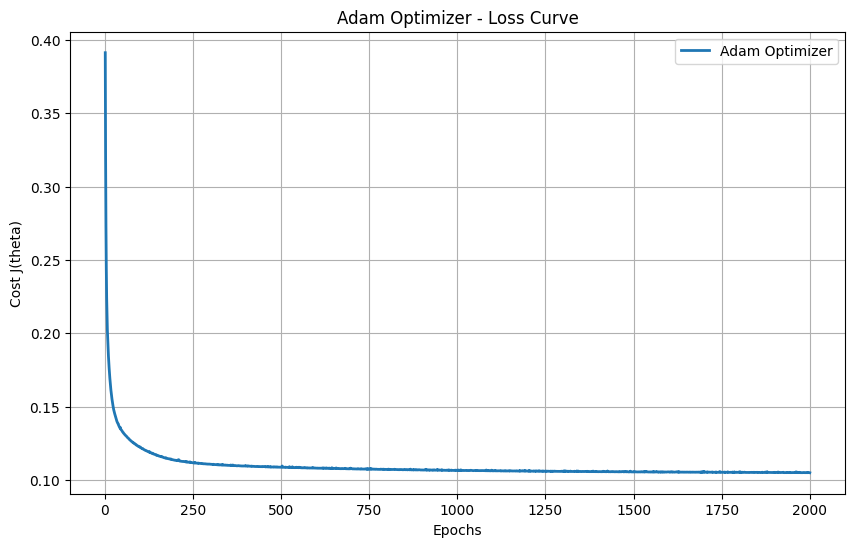

In [5]:

# Plot Adam Loss Curve

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    range(1, epochs_adam + 1),
    cost_history_adam,
    label='Adam Optimizer',
    linewidth=2
)

plt.xlabel('Epochs')
plt.ylabel('Cost J(theta)')
plt.title('Adam Optimizer - Loss Curve')
plt.legend()
plt.grid(True)
plt.show()


In [6]:

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Prepare test data
X_test_adam = np.c_[
    np.ones(X_test_scaled.shape[0]),
    X_test_scaled
]

# Make predictions
y_pred_scaled_adam = X_test_adam @ theta_adam

# Convert predictions to original scale
y_pred_adam = scaler_y.inverse_transform(
    y_pred_scaled_adam.reshape(-1, 1)
).ravel()

# Actual test values
y_actual = y_test_raw.to_numpy()

# Calculate evaluation metrics
mse_adam = mean_squared_error(y_actual, y_pred_adam)
rmse_adam = np.sqrt(mse_adam)
mae_adam = mean_absolute_error(y_actual, y_pred_adam)
r2_adam = r2_score(y_actual, y_pred_adam)

print("Adam - Test Results")
print("-------------------------")
print("MSE:", round(mse_adam, 4))
print("RMSE:", round(rmse_adam, 4))
print("MAE:", round(mae_adam, 4))
print("R2 Score:", round(r2_adam, 4))


Adam - Test Results
-------------------------
MSE: 68.5586
RMSE: 8.28
MAE: 6.0796
R2 Score: 0.7702



## Results and Discussion

In this experiment, Polynomial Regression (degree = 2) was trained using the Adam optimizer implemented from scratch with NumPy.

### Adam Experimental Results

| Metric | Result |
|---|---|
| Final Training Cost | 0.104904 |
| Test MSE | 68.5586 |
| Test RMSE | 8.2800 |
| Test MAE | 6.0796 |
| Test R2 | 0.7702 |

### Discussion

Adam combines two important optimization concepts: Momentum and adaptive learning rates.

The first moment estimates the moving average of gradients, while the second moment estimates the moving average of squared gradients.

Bias correction was applied to both estimates during training.

Adam successfully reduced the training cost from 0.5 to 0.104904 over 2000 epochs.

It achieved the lowest final training cost among the five tested optimizers.

However, SGD achieved a slightly better test RMSE and R2 score.

### Comparison of the Five Optimizers

| Optimizer | Final Training Cost | Test RMSE | Test R2 |
|---|---|---|---|
| GD | 0.112916 | 8.3541 | 0.7661 |
| SGD | 0.105816 | 8.2682 | 0.7708 |
| Mini-Batch GD | 0.109029 | 8.2992 | 0.7691 |
| RMSprop | 0.105167 | 8.2814 | 0.7701 |
| Adam | 0.104904 | 8.2800 | 0.7702 |

### Conclusion

All five optimizers successfully trained the Polynomial Regression model.

Adam achieved the lowest final training cost, while SGD achieved the lowest test RMSE.

The differences in test performance were relatively small.

Momentum can influence convergence, but it does not guarantee better test performance.

Since the optimizers used different learning rates and numbers of parameter updates, their convergence speeds cannot be compared fairly using epoch counts alone.

Overall, the experiment demonstrates how different optimization algorithms can train the same Polynomial Regression model while producing slightly different results.
